# Hand Gesture Recognition — Assignment 2 experiments

**Computer Vision — Assignment 2 (continuation of A1)**

This notebook runs top to bottom. The heavy work lives in `scripts/` and `src/`;
every number shown here is read from `results/a2/*.csv`, which those scripts write.

* `A2_RETRAIN=1` re-runs each stage's script before reading its results
  (otherwise the saved results are used, so the notebook runs in about a minute).
* `FAST_MODE=1` shortens every training stage (smoke test). FAST runs read and
  write `*_fast.csv`, so they can never be mistaken for real results.

In [1]:
%matplotlib inline

import os
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

from src.config import FAST, FIG_DIR, RESULTS_DIR, out_name

RETRAIN = os.environ.get("A2_RETRAIN") == "1"


def run_stage(script, *args, python=sys.executable):
    """Run one stage script and show the tail of its log."""
    proc = subprocess.run([python, script, *args], capture_output=True, text=True,
                          encoding="utf-8", errors="replace")
    print("\n".join(proc.stdout.splitlines()[-25:]))
    if proc.returncode:
        print(proc.stderr[-3000:])
        raise RuntimeError(f"{script} failed")


print(f"python {sys.version.split()[0]} | retrain {RETRAIN} | fast {FAST}")

python 3.14.0 | retrain False | fast False


## Stage 0 — reproduce the A1 baseline before changing anything

The A1 code was refactored into `src/` (`data.py`, `train.py`, `models.py`,
`metrics.py`). Before any A2 change, the refactored code must reproduce the A1
ResNet-18 result: **acc 0.945, macro-F1 0.947, 11 errors, all thumb→peace**.

Seed 42 is the A1 seed and runs on the A1 environment (torch 2.14.0+cpu), so it
should match exactly. Seeds 43 and 44 re-run the *unchanged* A1 recipe to show how
much of 0.945 is seed luck. These three runs are also the **B0** baseline for Stage 3.

A bit-exact reproduction needs the A1 environment (torch 2.14.0+cpu, `requirements.txt`):
set `A1_PYTHON` to that interpreter. In the A2 environment the numbers can differ slightly.

In [2]:
if RETRAIN:
    run_stage("scripts/stage0_reproduce.py", "--device", "cpu", python=os.environ.get("A1_PYTHON", sys.executable))

res0 = pd.read_csv(RESULTS_DIR / out_name("stage0_reproduce"))
cols = ["seed", "device", "acc", "macro_f1", "n_errors", "error_pattern",
        "acc_fist2_dark", "acc_peace2", "acc_thumb2", "best_val_acc", "train_seconds"]
display(res0[cols].round(4))
print(f"A1 reference          : acc 0.9450   macro-F1 0.9474   11 errors (thumb->peace:11)")
print(f"seed 42 reproduction  : acc {res0.acc[0]:.4f}   macro-F1 {res0.macro_f1[0]:.4f}   "
      f"{res0.n_errors[0]} errors ({res0.error_pattern[0]})")
print(f"B0 over {len(res0)} seeds    : acc {res0.acc.mean():.4f} ± {res0.acc.std(ddof=1):.4f}   "
      f"macro-F1 {res0.macro_f1.mean():.4f} ± {res0.macro_f1.std(ddof=1):.4f}")

,seed,device,acc,macro_f1,n_errors,error_pattern,acc_fist2_dark,acc_peace2,acc_thumb2,best_val_acc,train_seconds
0,42,cpu,0.945,0.9474,11,thumb->peace:11,1.0,1.0,0.8625,0.9694,524.5
1,43,cpu,0.890,0.8909,22,"thumb->fist:10, thumb->peace:12",1.0,1.0,0.7250,1.0000,518.2
2,44,cpu,0.905,0.9088,19,"thumb->fist:1, thumb->peace:18",1.0,1.0,0.7625,0.9694,516.8


A1 reference          : acc 0.9450   macro-F1 0.9474   11 errors (thumb->peace:11)
seed 42 reproduction  : acc 0.9450   macro-F1 0.9474   11 errors (thumb->peace:11)
B0 over 3 seeds    : acc 0.9133 ± 0.0284   macro-F1 0.9157 ± 0.0289


### B0 training curves (3 seeds)

The dashed line marks the unfreeze point: 6 head-only epochs, then 12 full fine-tune epochs.
Validation is the A1 one: the last 20% of every training clip. It is drawn from the
same recordings as the training frames, so it overstates test accuracy (A1 §5).

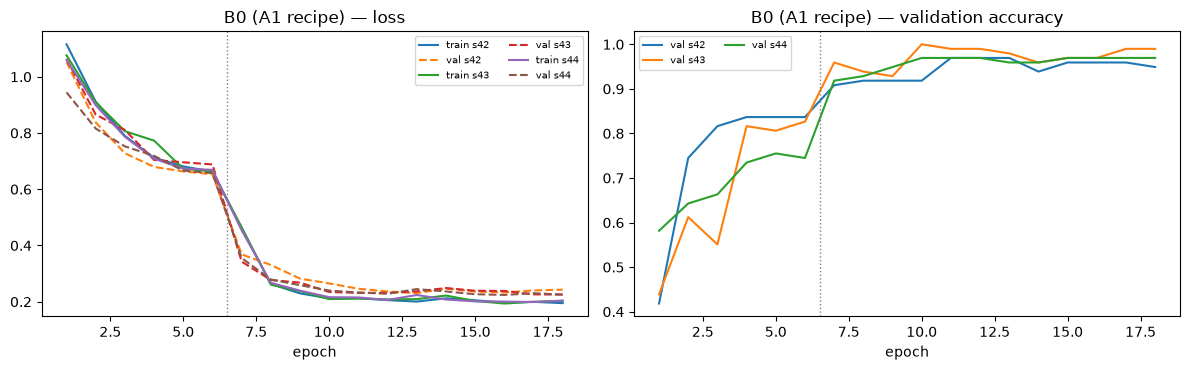

In [3]:
hist0 = pd.read_csv(RESULTS_DIR / out_name("stage0_history"))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for seed, h in hist0.groupby("seed"):
    axes[0].plot(h.epoch, h.train_loss, label=f"train s{seed}")
    axes[0].plot(h.epoch, h.val_loss, ls="--", label=f"val s{seed}")
    axes[1].plot(h.epoch, h.val_acc, label=f"val s{seed}")
n_head = int((hist0[hist0.seed == hist0.seed.iloc[0]].stage == "head").sum())
for ax, title in zip(axes, ["loss", "validation accuracy"]):
    ax.axvline(n_head + 0.5, color="grey", ls=":", lw=1)
    ax.set_xlabel("epoch")
    ax.set_title(f"B0 (A1 recipe) — {title}")
    ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
fig.savefig(FIG_DIR / out_name("stage0_curves", "png"), dpi=120, bbox_inches="tight")
plt.show()

### What the A1 centre crop threw away on the misclassified frames

A1 fed the model the central 1072×1072 square of each 1072×1920 portrait frame.
The figure re-reads every seed-42 error from the original `.MOV` and outlines that
square in red: everything outside it was never seen by the model.

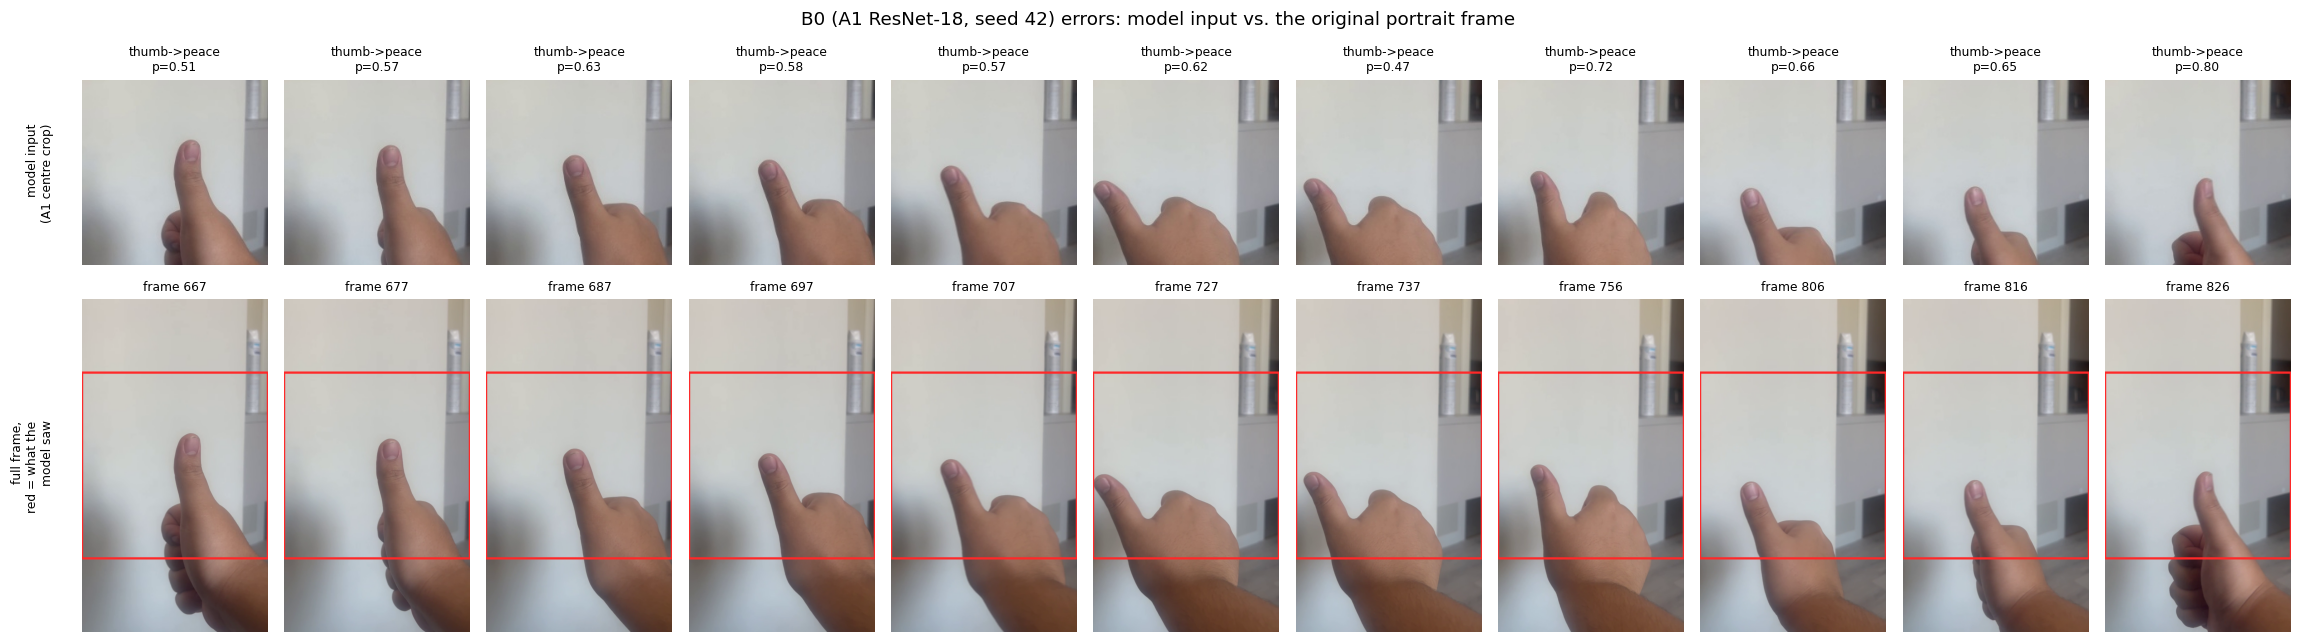

In [4]:
if RETRAIN or not (FIG_DIR / "stage0_errors_fullframe.png").exists():
    run_stage("scripts/inspect_closeups.py")
display(Image(filename=str(FIG_DIR / "stage0_errors_fullframe.png")))

## Stage 1 — data

* A1 clips re-read from the `.MOV` files (full portrait frames for the hand pipeline;
  the A1 224 px centre squares stay B0's input). `dataset/` is never rewritten.
* New A2 clips from `raw_v2/` — **test only**.
* HaGRID (fist / peace / like→thumb), **training data + a held-out-people test set**,
  split by `user_id`; faces blurred before any model sees them.

,source,split,fist,peace,thumb,total
0,hagrid,test,92,100,100,292
1,hagrid,train,376,400,400,1176
2,own,test,420,420,440,1280
3,own,train,147,146,129,422
4,own,val,33,34,31,98


,external_share_of_train,external_share_of_all,synthetic_share
0,0.7359,0.4492,0.0


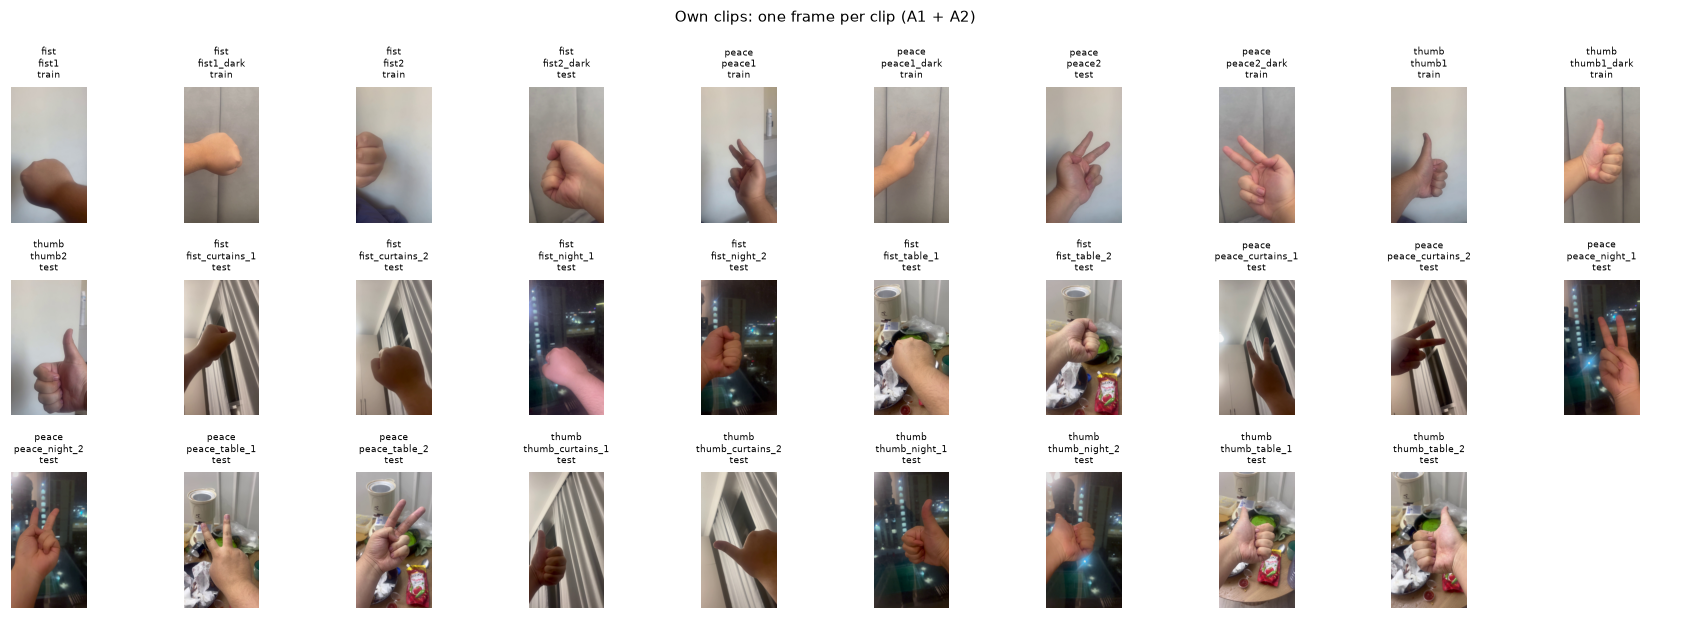

In [5]:
if RETRAIN:
    if not (RESULTS_DIR.parents[1] / "dataset_v2" / "hagrid" / "metadata_hagrid.csv").exists():
        run_stage("scripts/download_hagrid.py")
        run_stage("scripts/blur_hagrid_faces.py")
    run_stage("scripts/build_dataset_v2.py")
    run_stage("scripts/stage1_report.py")

display(pd.read_csv(RESULTS_DIR / "stage1_dataset_table.csv"))
display(pd.read_csv(RESULTS_DIR / "stage1_shares.csv"))
display(Image(filename=str(FIG_DIR / "stage1_contact_own.png")))

## Stage 2 — hand pipeline cache (MediaPipe → crop → SAM 2.1 mask)

,source,environment,split,images,detected,masks
0,hagrid,hagrid,test,292,0.856,0
1,hagrid,hagrid,train,1176,0.841,989
2,own,a1_room,test,200,0.945,0
3,own,a1_room,train,422,0.936,395
4,own,a1_room,val,98,0.908,0
5,own,curtains,test,360,0.939,0
6,own,night,test,360,0.939,0
7,own,table,test,360,0.983,0


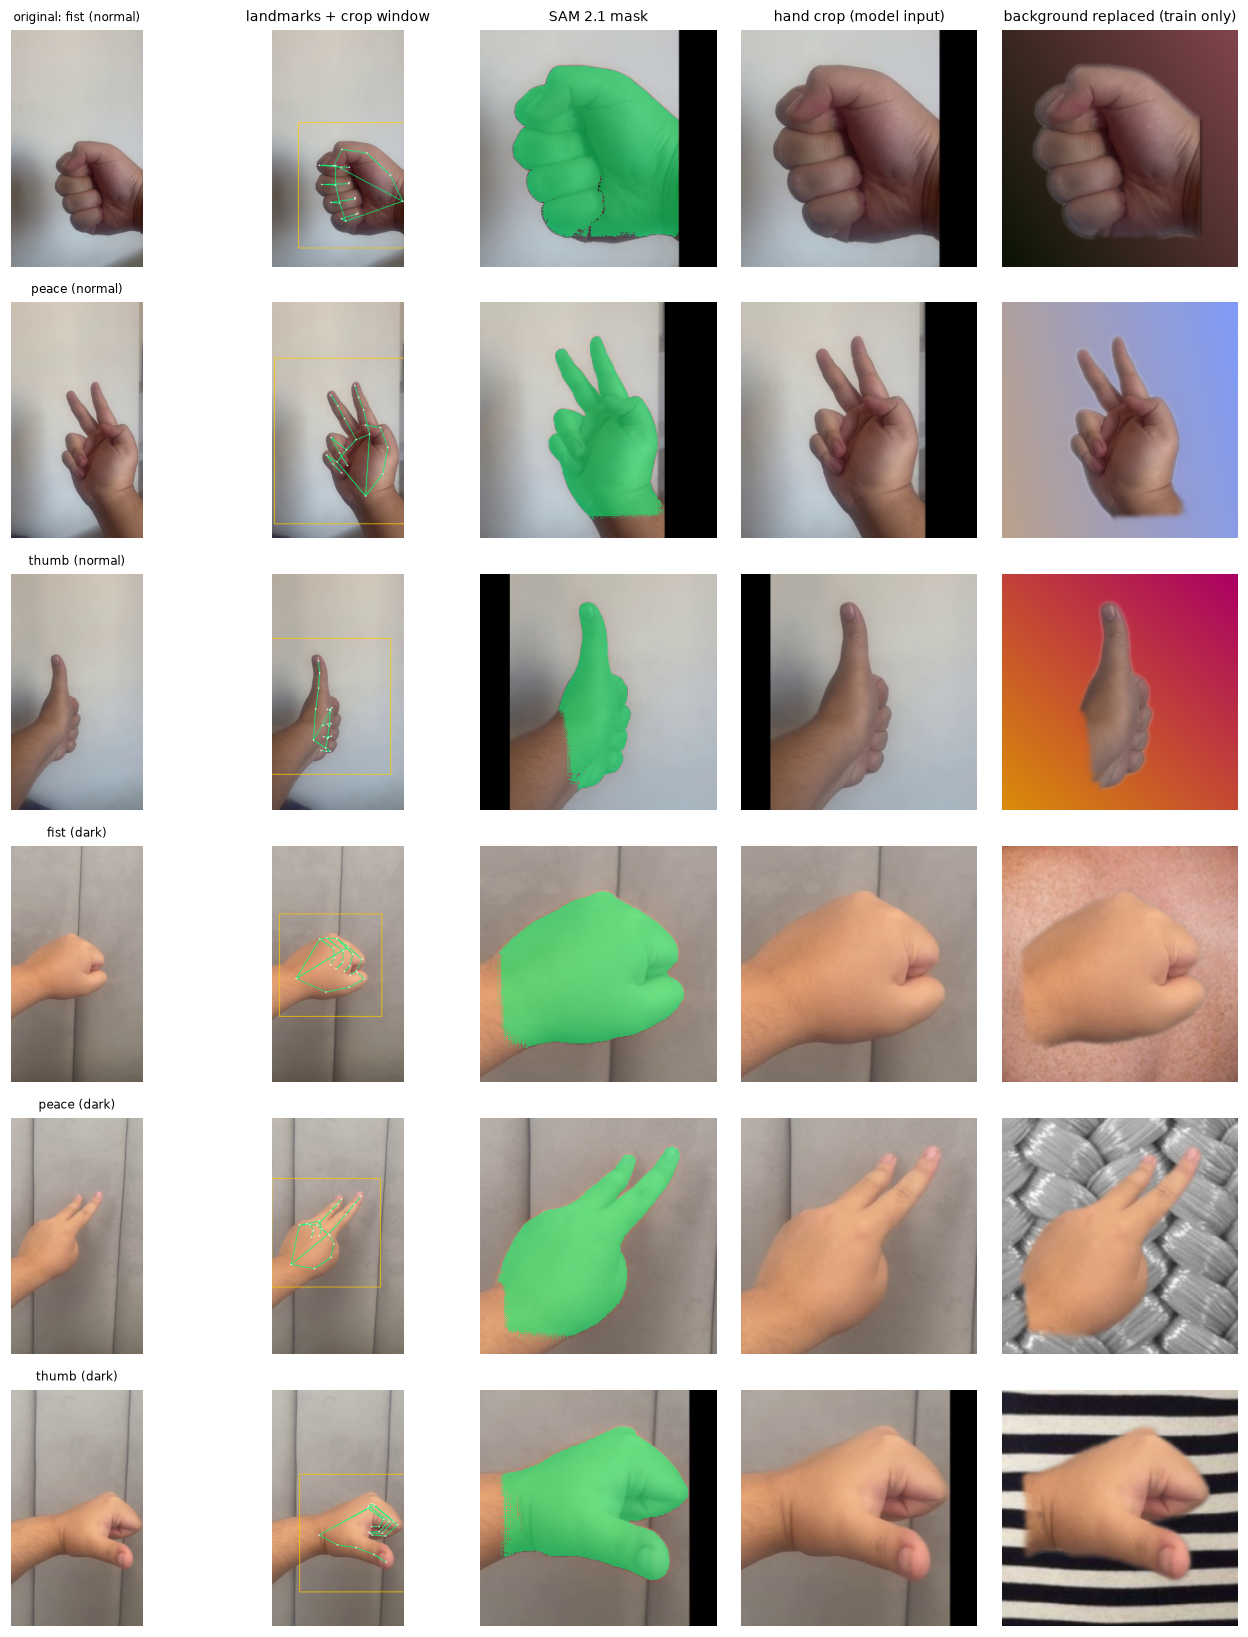

A1 close-up errors vs the A1 centre square (landmarks outside it):


,video,b0_error_all_seeds,images,detected,mean_frac_landmarks_outside_centre,any_landmark_outside
0,fist2_dark,False,60,0.900,0.131,0.550
1,peace2,False,60,1.000,0.093,0.767
2,thumb2,False,69,0.957,0.316,0.884
3,thumb2,True,11,0.818,0.275,0.818


In [6]:
if RETRAIN:
    run_stage("scripts/prepare_textures.py")
    import torch
    run_stage("scripts/precompute_hands.py", "--device", "cuda" if torch.cuda.is_available() else "cpu")
    run_stage("scripts/stage2_figure.py")

display(pd.read_csv(RESULTS_DIR / "stage2_detection.csv").round(3))
display(Image(filename=str(FIG_DIR / "stage2_pipeline.png")))
print("A1 close-up errors vs the A1 centre square (landmarks outside it):")
display(pd.read_csv(RESULTS_DIR / "stage2_closeups.csv").round(3))

## Stage 3 — baseline vs SOTA (3 seeds each)

| model | what changes |
|---|---|
| B0 | A1 ResNet-18 on the A1 centre square (Stage 0 weights) |
| S1 | + hand crop (MediaPipe) |
| S2 | + background replacement (SAM 2.1 masks, p = 0.5, train only) |
| S3 | + HaGRID training data |
| S4-probe / S4 | DINOv2 ViT-S/14 on the S3 pipeline: linear probe / light fine-tune |
| S5 | MLP on the 21 MediaPipe landmarks (no hand → counted as an error) |

In [7]:
if RETRAIN:
    run_stage("scripts/stage3_train.py")
    run_stage("scripts/stage3_analyze.py")
    run_stage("scripts/stage3_clip_ci.py")
    run_stage("scripts/stage3_latency.py")

print("Accuracy per test set, mean ± std over 3 seeds")
display(pd.read_csv(RESULTS_DIR / "stage3_per_env.csv"))
summ = pd.read_csv(RESULTS_DIR / "stage3_summary.csv")
display(summ.round(3))
print("Clip-level 95% CI (whole clips resampled; frames of one clip are near-duplicates)")
display(pd.read_csv(RESULTS_DIR / "stage3_clip_ci.csv").round(3))

Accuracy per test set, mean ± std over 3 seeds


,model,a1_test,new_envs,hagrid_people,curtains,night,table
0,B0,0.913 ± 0.028,0.586 ± 0.010,0.486 ± 0.055,0.654 ± 0.002,0.606 ± 0.038,0.499 ± 0.066
1,S1,0.938 ± 0.018,0.861 ± 0.010,0.696 ± 0.048,0.866 ± 0.014,0.922 ± 0.019,0.795 ± 0.042
2,S2,0.945 ± 0.022,0.912 ± 0.009,0.605 ± 0.050,0.892 ± 0.010,0.944 ± 0.006,0.900 ± 0.024
3,S3,0.955 ± 0.018,0.915 ± 0.004,0.978 ± 0.002,0.898 ± 0.011,0.956 ± 0.008,0.893 ± 0.007
4,S4-probe,0.828 ± 0.028,0.778 ± 0.047,0.949 ± 0.003,0.773 ± 0.063,0.878 ± 0.048,0.683 ± 0.044
5,S4,0.983 ± 0.013,0.951 ± 0.012,0.979 ± 0.007,0.930 ± 0.015,0.976 ± 0.014,0.947 ± 0.008
6,S5,0.925 ± 0.009,0.888 ± 0.007,0.839 ± 0.000,0.849 ± 0.004,0.913 ± 0.016,0.901 ± 0.006


,model,test_set,n_images,n_seeds,acc_mean,acc_std,acc_ci_low,acc_ci_high,f1_mean,f1_std,detection_rate
0,B0,a1_test,200,3,0.913,0.028,0.877,0.947,0.916,0.029,0.945
1,S1,a1_test,200,3,0.938,0.018,0.910,0.967,0.940,0.018,0.945
2,S2,a1_test,200,3,0.945,0.022,0.917,0.972,0.947,0.022,0.945
3,S3,a1_test,200,3,0.955,0.018,0.930,0.978,0.956,0.018,0.945
4,S4-probe,a1_test,200,3,0.828,0.028,0.780,0.875,0.831,0.024,0.945
5,S4,a1_test,200,3,0.983,0.013,0.967,0.997,0.984,0.012,0.945
6,S5,a1_test,200,3,0.925,0.009,0.887,0.958,0.950,0.009,0.945
7,B0,curtains,360,3,0.654,0.002,0.608,0.697,0.631,0.014,0.939
8,S1,curtains,360,3,0.866,0.014,0.832,0.899,0.859,0.012,0.939
9,S2,curtains,360,3,0.892,0.010,0.860,0.922,0.889,0.009,0.939


Clip-level 95% CI (whole clips resampled; frames of one clip are near-duplicates)


,test_group,model,n_clips,acc_seed_mean,clip_ci_low,clip_ci_high
0,a1_test,B0,3,0.913,0.913,0.913
1,a1_test,S1,3,0.938,0.938,0.938
2,a1_test,S2,3,0.945,0.945,0.945
3,a1_test,S3,3,0.955,0.955,0.955
4,a1_test,S4-probe,3,0.828,0.828,0.828
5,a1_test,S4,3,0.983,0.983,0.983
6,a1_test,S5,3,0.925,0.925,0.925
7,new_envs,B0,18,0.586,0.506,0.668
8,new_envs,S1,18,0.861,0.775,0.942
9,new_envs,S2,18,0.912,0.848,0.974


Ablation: change in accuracy / macro-F1 from each step, paired by seed


,step,model,test_set,n_seeds,d_acc_mean,d_acc_std,d_f1_mean,d_f1_std
0,crop,S1 vs B0,a1_test,3,0.025,0.013,0.024,0.013
1,crop,S1 vs B0,new_envs,3,0.275,0.009,0.290,0.007
2,crop,S1 vs B0,hagrid_people,3,0.210,0.055,0.280,0.063
3,crop,S1 vs B0,curtains,3,0.212,0.013,0.228,0.003
4,crop,S1 vs B0,night,3,0.316,0.018,0.330,0.026
5,crop,S1 vs B0,table,3,0.296,0.030,0.328,0.048
6,background replacement,S2 vs S1,a1_test,3,0.007,0.010,0.007,0.010
7,background replacement,S2 vs S1,new_envs,3,0.051,0.019,0.058,0.022
8,background replacement,S2 vs S1,hagrid_people,3,-0.091,0.005,-0.091,0.012
9,background replacement,S2 vs S1,curtains,3,0.026,0.008,0.030,0.009


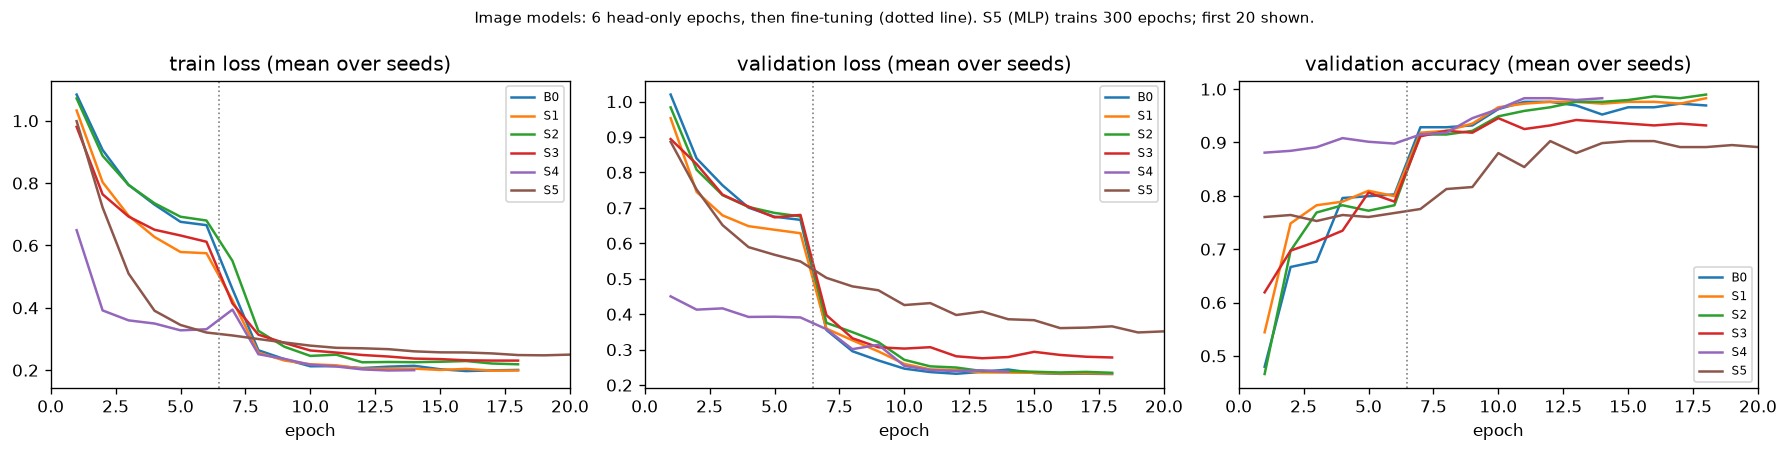

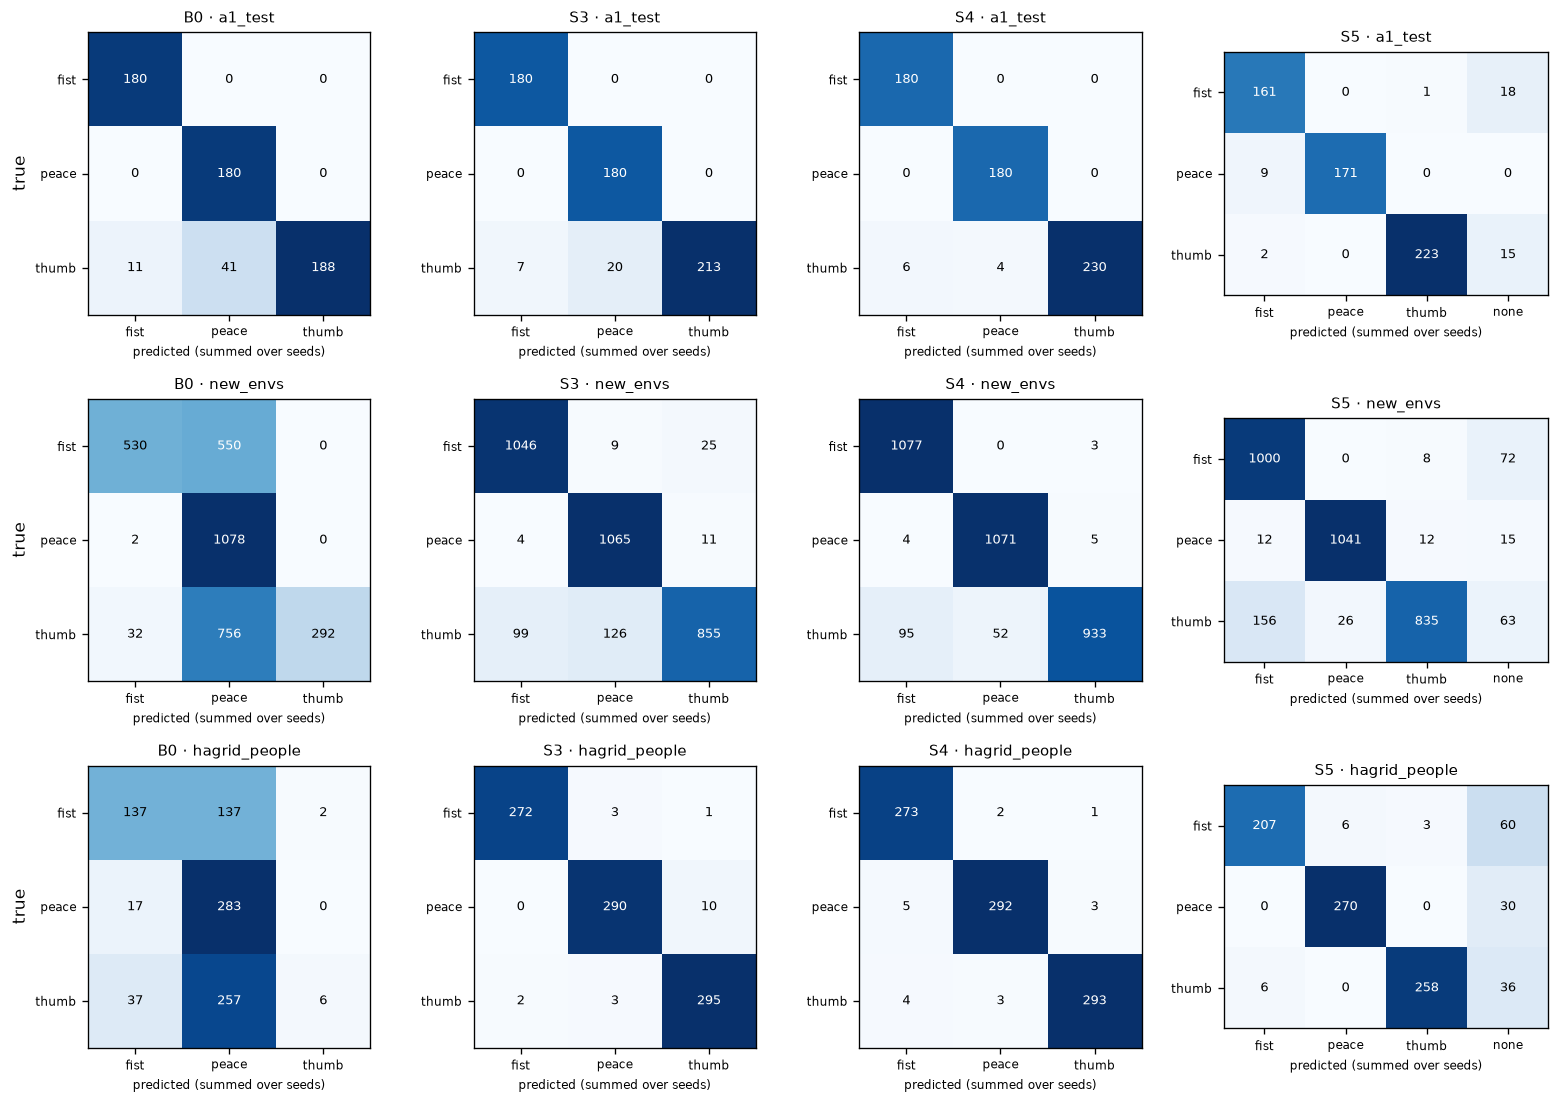

In [8]:
print("Ablation: change in accuracy / macro-F1 from each step, paired by seed")
display(pd.read_csv(RESULTS_DIR / "stage3_ablation.csv").round(3))
display(Image(filename=str(FIG_DIR / "stage3_curves.png")))
display(Image(filename=str(FIG_DIR / "stage3_confusion.png")))

In [9]:
print("CPU latency at batch size 1")
display(pd.read_csv(RESULTS_DIR / "stage3_latency.csv")[["kind", "name", "median_ms", "p95_ms", "fps_median"]])
display(pd.read_csv(RESULTS_DIR / "stage3_model_size.csv"))

CPU latency at batch size 1


,kind,name,median_ms,p95_ms,fps_median
0,component,MediaPipe Hand Landmarker,21.4,22.4,46.7
1,component,SAM 2.1 hiera-tiny (256 px crop),2187.9,2322.7,0.5
2,component,ResNet-18 classifier (224 px),22.5,26.4,44.4
3,component,DINOv2 ViT-S/14 classifier (224 px),57.2,63.3,17.5
4,component,Landmark MLP,0.1,0.1,15186.0
5,end-to-end,B0: centre square + ResNet-18,20.3,27.3,49.4
6,end-to-end,S3: MediaPipe + crop + ResNet-18,54.1,61.9,18.5
7,end-to-end,S4: MediaPipe + crop + DINOv2,84.9,96.9,11.8
8,end-to-end,S5: MediaPipe + landmark MLP,21.7,22.4,46.1
9,end-to-end,S3 + SAM 2.1 mask overlay (app option),2144.4,2311.8,0.5


,model,parameters,size_mb
0,ResNet-18 (B0-S3),11178051.0,44.8
1,DINOv2 ViT-S/14 + head (S4),22058883.0,88.3
2,Landmark MLP (S5),16643.0,0.1
3,SAM 2.1 hiera-tiny,31440721.0,125.8
4,MediaPipe Hand Landmarker (.task),NaN,7.8


### The A1 close-up errors, before and after

,filepath,b0_correct_seeds,S4_correct_seeds,n_seeds,detected
0,dataset/thumb/thumb2_f00667.jpg,0,3,3,True
1,dataset/thumb/thumb2_f00677.jpg,0,3,3,False
2,dataset/thumb/thumb2_f00687.jpg,0,3,3,True
3,dataset/thumb/thumb2_f00697.jpg,0,3,3,True
4,dataset/thumb/thumb2_f00707.jpg,0,3,3,True
5,dataset/thumb/thumb2_f00727.jpg,0,0,3,True
6,dataset/thumb/thumb2_f00737.jpg,0,2,3,True
7,dataset/thumb/thumb2_f00756.jpg,0,3,3,False
8,dataset/thumb/thumb2_f00806.jpg,0,3,3,True
9,dataset/thumb/thumb2_f00816.jpg,0,3,3,True


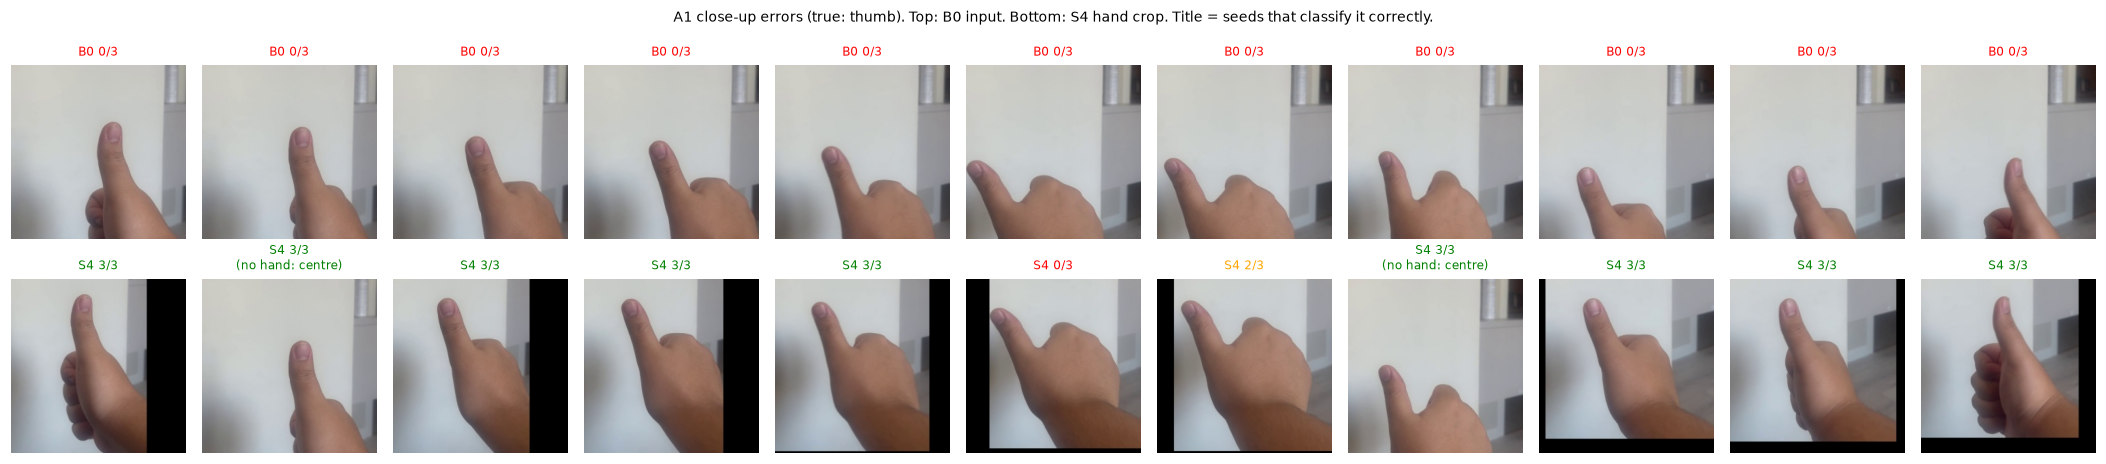

In [10]:
display(pd.read_csv(RESULTS_DIR / "stage3_closeups.csv"))
display(Image(filename=str(FIG_DIR / "stage3_closeups_before_after.png")))

## Stage 4 — explainability: hand or background?

Grad-CAM (ResNet-18) and attention rollout (DINOv2) on each model's own input, and the
share of the heatmap that falls on the SAM 2.1 hand mask. The mask's area is the
chance level (a heatmap spread evenly over the image).

,model,method,images,heat_on_hand,hand_area,lift,acc
0,B0,Grad-CAM,1219,0.396,0.256,1.574,0.658
1,S2,Grad-CAM,1219,0.510,0.274,1.889,0.936
2,S3,Grad-CAM,1219,0.489,0.274,1.798,0.930
3,S4,attention rollout,1219,0.289,0.274,1.115,0.970


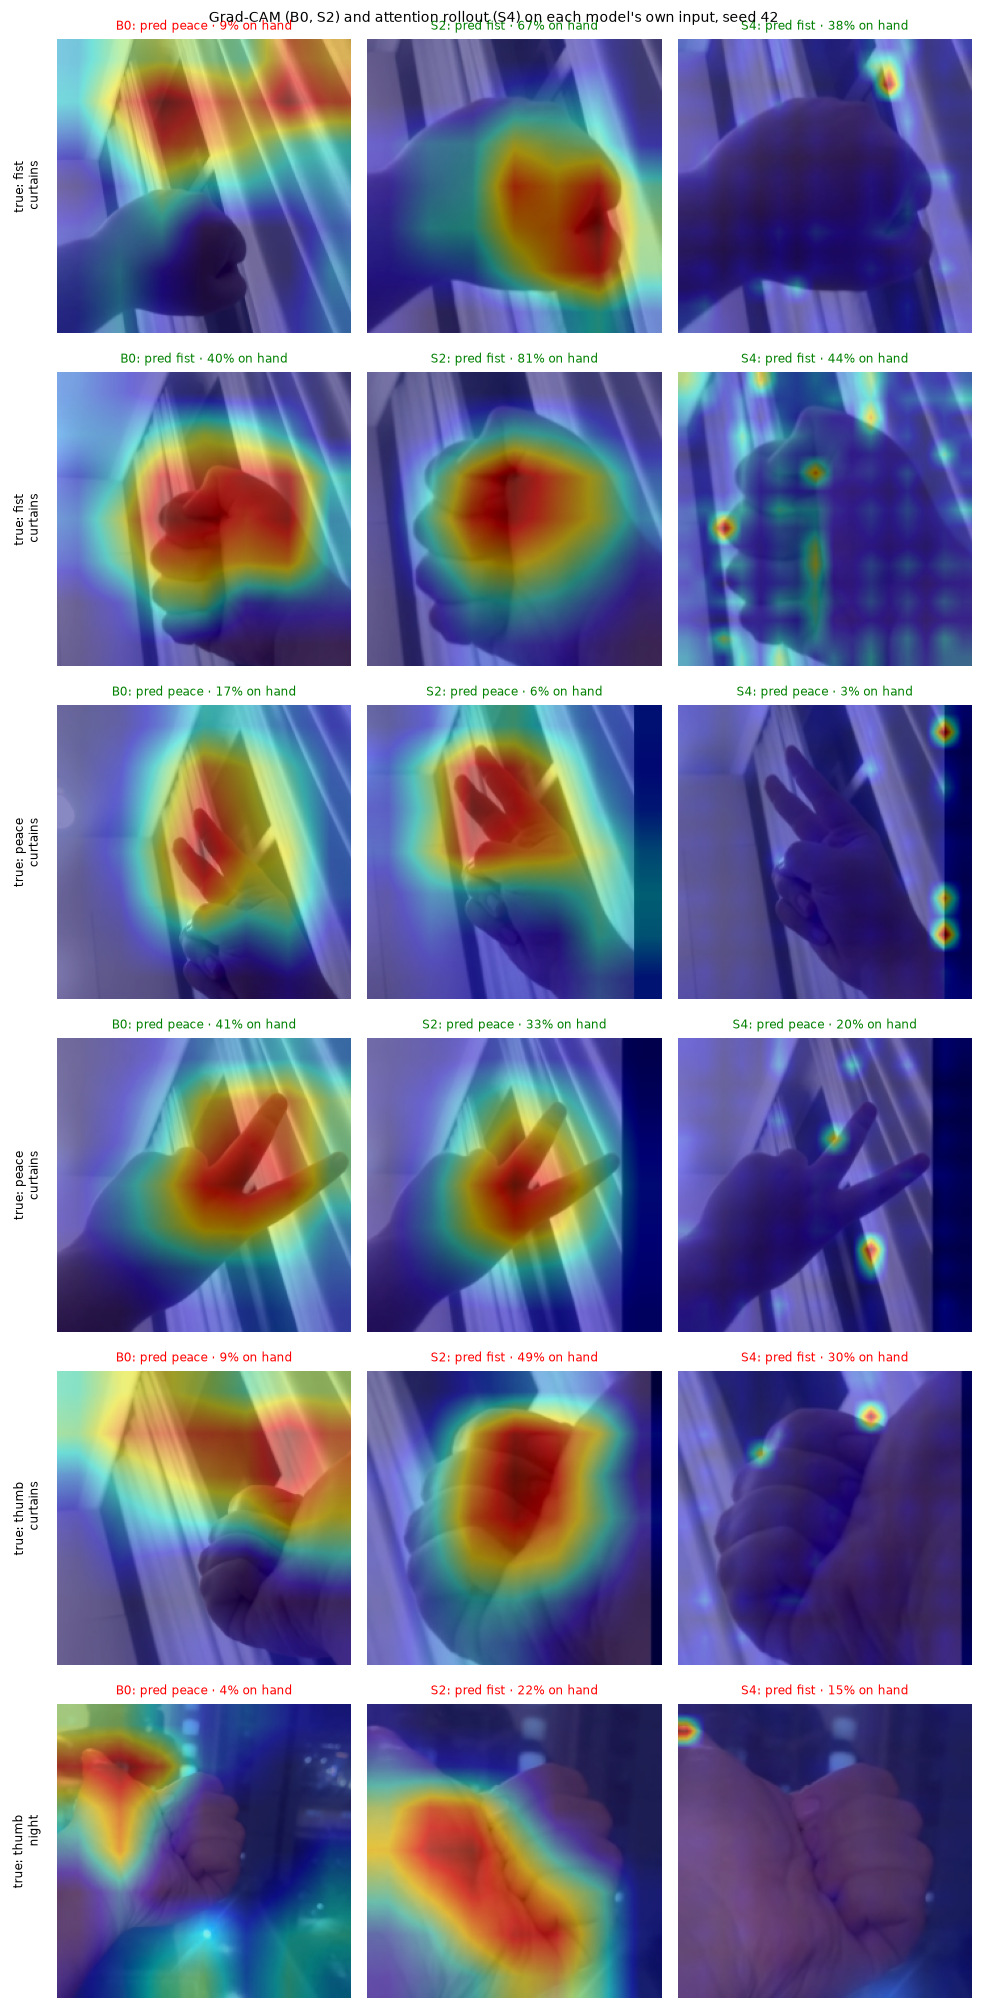

In [11]:
if RETRAIN:
    run_stage("scripts/stage4_explain.py")

display(pd.read_csv(RESULTS_DIR / "stage4_summary.csv").round(3))
display(Image(filename=str(FIG_DIR / "stage4_heatmaps.png")))

## Report charts

Built only from the CSVs above by `scripts/make_report_figures.py`.

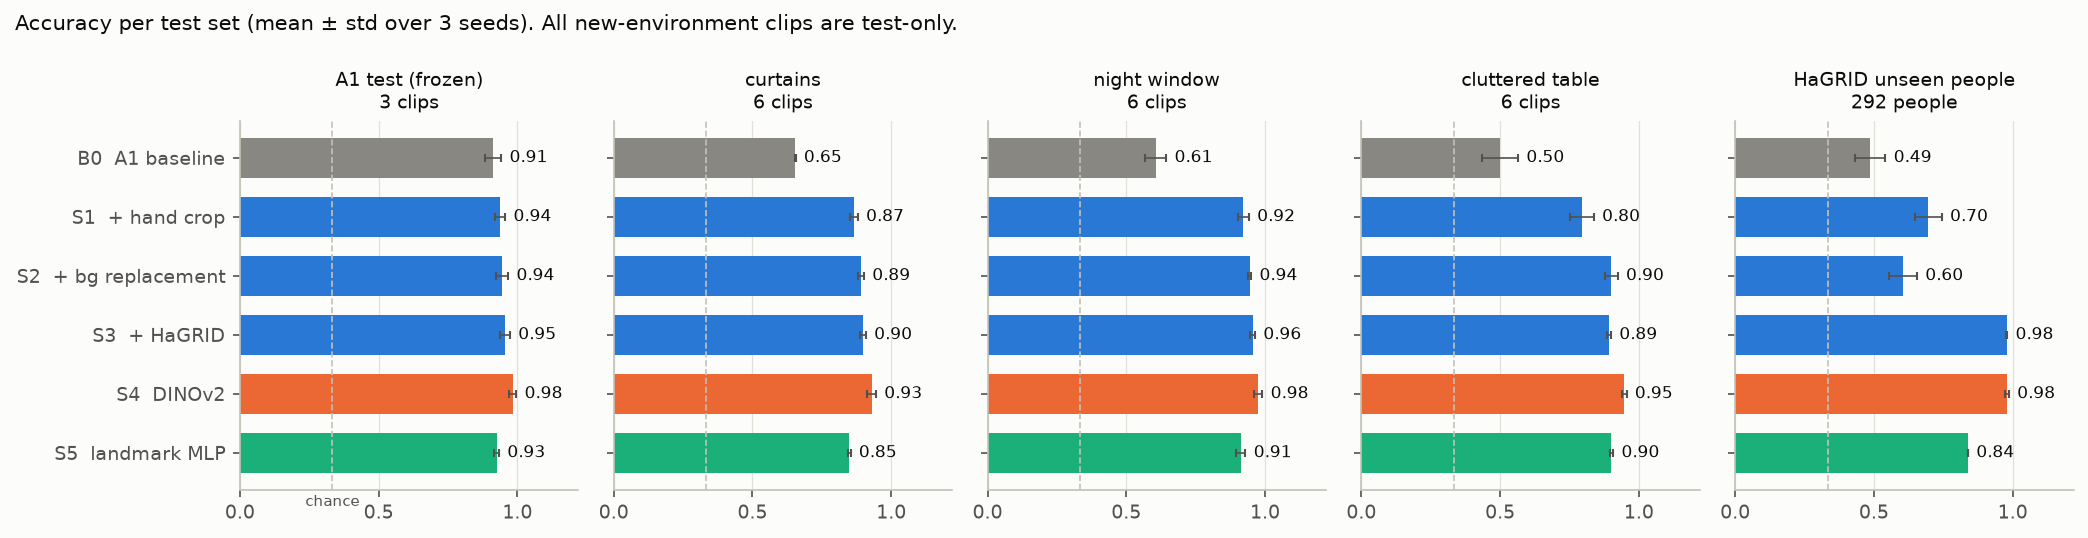

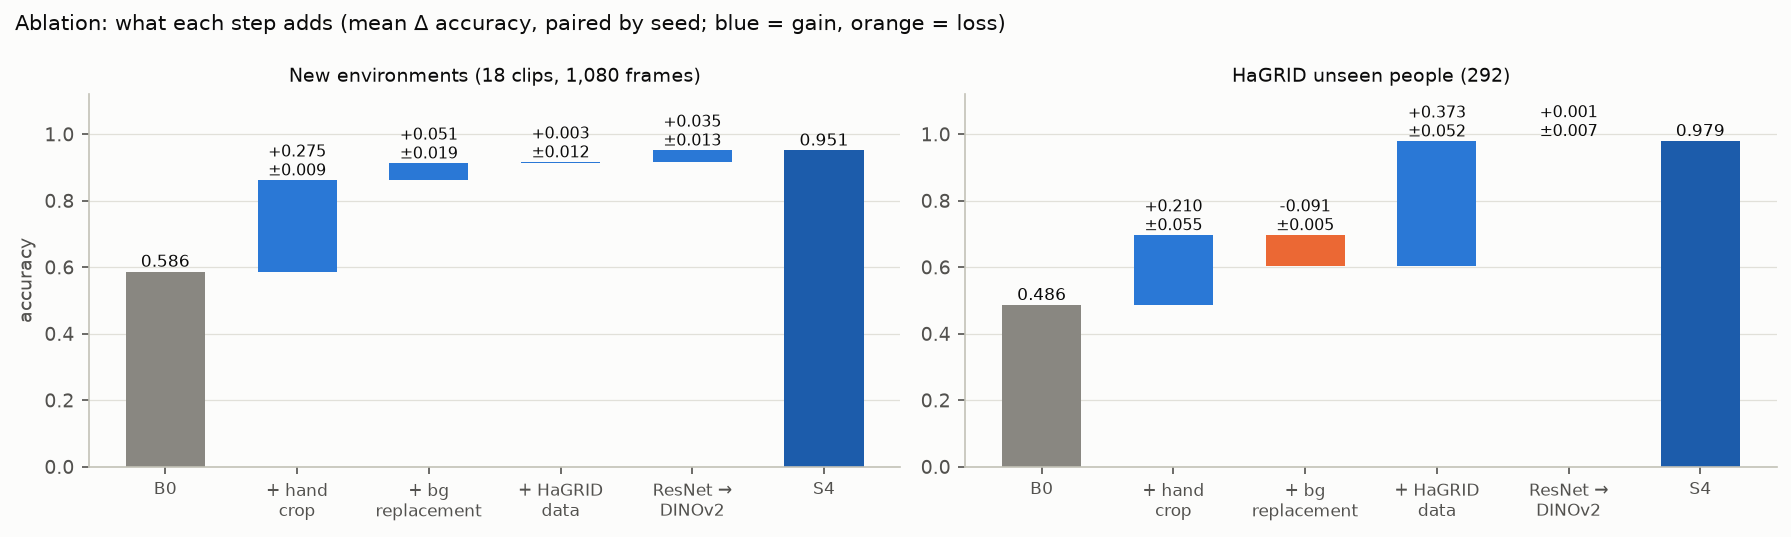

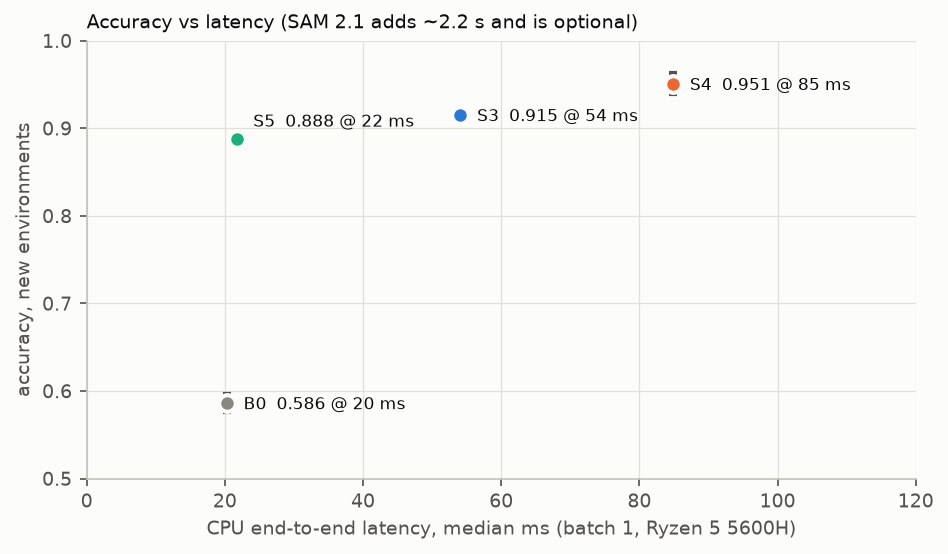

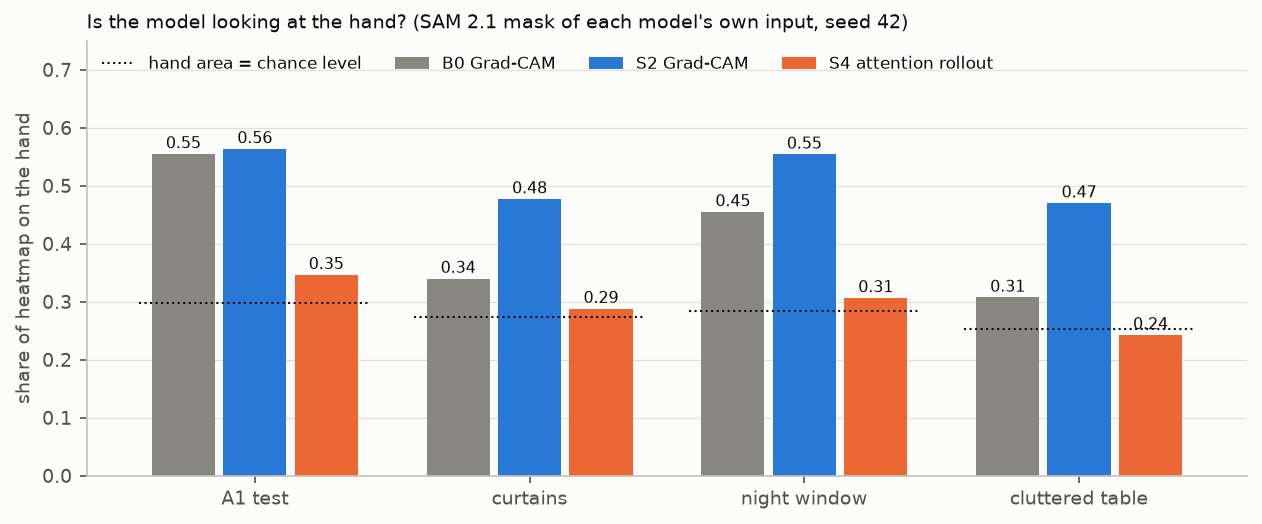

In [12]:
if RETRAIN:
    run_stage("scripts/make_report_figures.py")
for f in ["report_env_accuracy", "report_ablation", "report_accuracy_latency", "report_heat_on_hand"]:
    display(Image(filename=str(FIG_DIR / f"{f}.png")))